# Fase 2 y 6 — Pruebas de hipótesis y validación estadística

Las hipótesis están formuladas en `docs/02_hipotesis.md`. Nivel de significancia **α = 0,05**.

**Regla de decisión:** si el valor p < α se rechaza H0. Como la muestra es muy grande, se reporta también
el tamaño del efecto para distinguir entre significancia estadística y relevancia práctica.

In [1]:
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent))

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from src.config import ALPHA, FIGURES_DIR, PROCESSED_DIR, REPORTS_DIR
from src.stats_tests import (
    chi_square_test,
    kruskal_test,
    linear_fare_model,
    mann_whitney_test,
    normality_test,
    spearman_test,
)

sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.max_colwidth", 120)

df = pd.read_csv(PROCESSED_DIR / "uber_clean.csv", parse_dates=["fecha_local", "fecha"])
print(f"Viajes analizados: {len(df):,}")

Viajes analizados: 191,776


## 0. Supuesto de normalidad

Se verifica si las variables numéricas siguen una distribución normal para elegir el tipo de prueba.

In [2]:
pd.DataFrame([normality_test(df[c]) for c in ["fare_amount", "distancia_km", "tarifa_por_km"]])

,variable,estadistico,p_valor,asimetria,es_normal
0,fare_amount,3142.150461,0.0,2.931528,False
1,distancia_km,3057.346208,0.0,2.869648,False
2,tarifa_por_km,13566.017659,0.0,33.138106,False


Ninguna variable es normal (p < 0,05) y todas tienen asimetría positiva, por lo que se usan pruebas
**no paramétricas** (Spearman, Mann-Whitney U, Kruskal-Wallis) y chi-cuadrado para variables categóricas.

In [3]:
resultados = []

## H1 — A mayor distancia, mayor tarifa

In [4]:
resultados.append(
    spearman_test(df["distancia_km"], df["fare_amount"], "H1: Distancia vs. tarifa")
)
modelo = linear_fare_model(df["distancia_km"], df["fare_amount"])
print(f"Tarifa base estimada: {modelo['tarifa_base']:.2f} USD")
print(f"Costo por km estimado: {modelo['costo_por_km']:.2f} USD")
print(f"R²: {modelo['r_cuadrado']:.3f}")
resultados[-1]

Tarifa base estimada: 3.38 USD
Costo por km estimado: 2.35 USD
R²: 0.807


{'hipotesis': 'H1: Distancia vs. tarifa',
 'prueba': 'Correlación de Spearman',
 'estadistico': np.float64(0.8671916297778024),
 'p_valor': np.float64(0.0),
 'efecto': 'rho = 0.867 | Pearson r = 0.898',
 'decision': 'Se rechaza H0'}

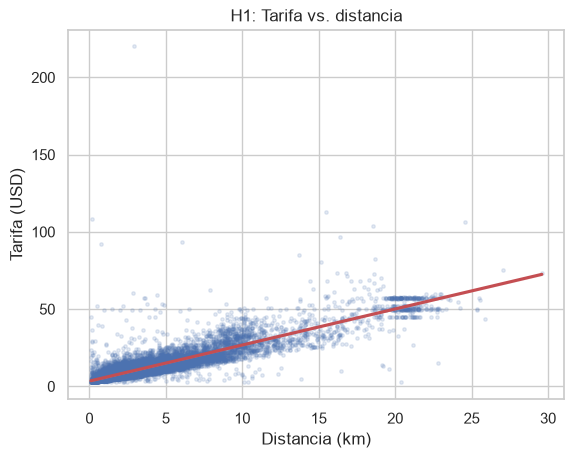

In [5]:
muestra = df.sample(min(len(df), 20_000), random_state=42)
ax = sns.regplot(
    data=muestra, x="distancia_km", y="fare_amount",
    scatter_kws={"alpha": 0.15, "s": 6}, line_kws={"color": "#C44E52"},
)
ax.set(title="H1: Tarifa vs. distancia", xlabel="Distancia (km)", ylabel="Tarifa (USD)")
plt.savefig(FIGURES_DIR / "03_h1_distancia_tarifa.png", dpi=120)
plt.show()

## H2 — La tarifa por km difiere en hora pico

In [6]:
pico = df.loc[df["es_hora_pico"], "tarifa_por_km"]
no_pico = df.loc[~df["es_hora_pico"], "tarifa_por_km"]
resultados.append(
    mann_whitney_test(pico, no_pico, "H2: Tarifa/km hora pico vs. no pico", ("pico", "no pico"))
)
resultados.append(
    mann_whitney_test(
        df.loc[df["es_hora_pico"], "fare_amount"], df.loc[~df["es_hora_pico"], "fare_amount"],
        "H2b: Tarifa hora pico vs. no pico", ("pico", "no pico"),
    )
)
resultados[-2:]

[{'hipotesis': 'H2: Tarifa/km hora pico vs. no pico',
  'prueba': 'Mann-Whitney U',
  'estadistico': np.float64(3983643917.0),
  'p_valor': np.float64(6.142759563329042e-303),
  'efecto': 'r biserial = 0.111 | mediana pico = 4.03, no pico = 3.73',
  'decision': 'Se rechaza H0'},
 {'hipotesis': 'H2b: Tarifa hora pico vs. no pico',
  'prueba': 'Mann-Whitney U',
  'estadistico': np.float64(3489121995.5),
  'p_valor': np.float64(2.3729285959542247e-19),
  'efecto': 'r biserial = -0.027 | mediana pico = 8.50, no pico = 8.50',
  'decision': 'Se rechaza H0'}]

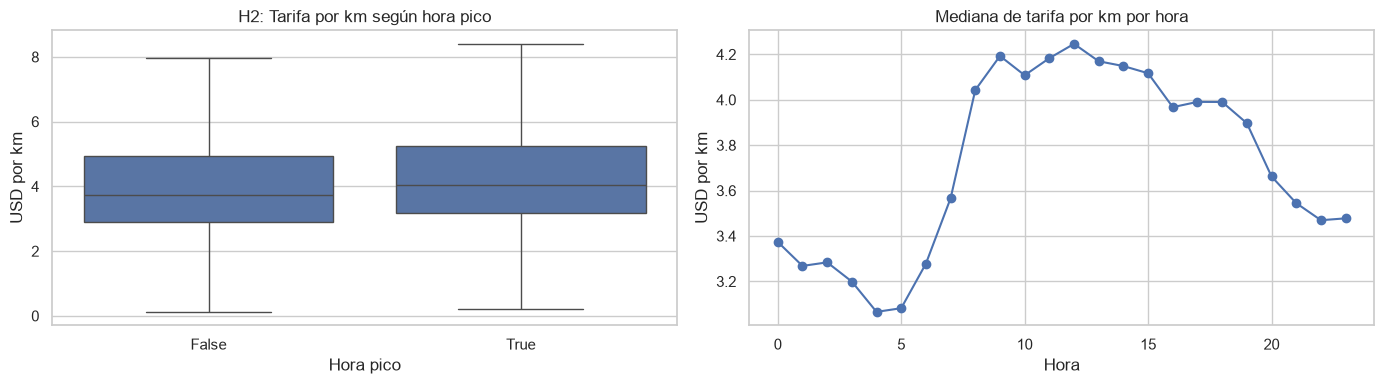

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.boxplot(data=df, x="es_hora_pico", y="tarifa_por_km", showfliers=False, ax=axes[0])
axes[0].set(title="H2: Tarifa por km según hora pico", xlabel="Hora pico", ylabel="USD por km")
df.groupby("hora")["tarifa_por_km"].median().plot(marker="o", ax=axes[1])
axes[1].set(title="Mediana de tarifa por km por hora", xlabel="Hora", ylabel="USD por km")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "03_h2_hora_pico.png", dpi=120)
plt.show()

## H3 — La tarifa difiere entre semana y fin de semana

In [8]:
resultados.append(
    mann_whitney_test(
        df.loc[df["es_fin_de_semana"], "fare_amount"], df.loc[~df["es_fin_de_semana"], "fare_amount"],
        "H3: Tarifa fin de semana vs. entre semana", ("fin de semana", "entre semana"),
    )
)
resultados[-1]

{'hipotesis': 'H3: Tarifa fin de semana vs. entre semana',
 'prueba': 'Mann-Whitney U',
 'estadistico': np.float64(3752968052.5),
 'p_valor': np.float64(0.14919921614164625),
 'efecto': 'r biserial = 0.004 | mediana fin de semana = 8.50, entre semana = 8.50',
 'decision': 'No se rechaza H0'}

## H4 — La tarifa por km cambia entre años

In [9]:
resultados.append(kruskal_test(df, "tarifa_por_km", "anio", "H4: Tarifa/km entre años"))
ajuste = pd.Timestamp("2012-09-04")
resultados.append(
    mann_whitney_test(
        df.loc[df["fecha_local"] >= ajuste, "tarifa_por_km"],
        df.loc[df["fecha_local"] < ajuste, "tarifa_por_km"],
        "H4b: Tarifa/km después vs. antes de sep-2012", ("después", "antes"),
    )
)
df.groupby("anio")[["fare_amount", "tarifa_por_km"]].median()

,fare_amount,tarifa_por_km
anio,,
2009,7.7,3.552441
2010,7.7,3.501935
2011,7.7,3.528712
2012,8.5,3.705832
2013,9.5,4.134706
2014,9.5,4.236562
2015,9.5,4.315275


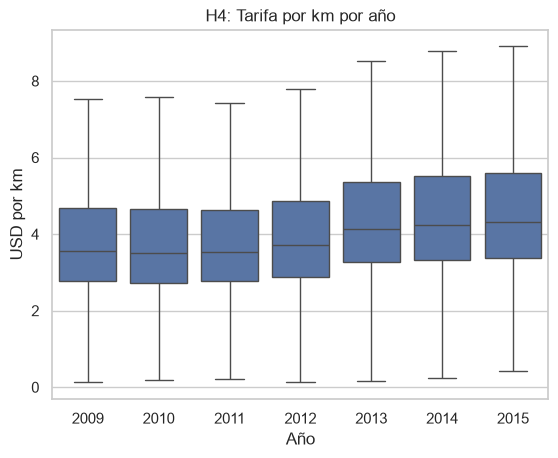

In [10]:
ax = sns.boxplot(data=df, x="anio", y="tarifa_por_km", showfliers=False)
ax.set(title="H4: Tarifa por km por año", xlabel="Año", ylabel="USD por km")
plt.savefig(FIGURES_DIR / "03_h4_anio.png", dpi=120)
plt.show()

## H5 — La tarifa difiere según el número de pasajeros

In [11]:
resultados.append(kruskal_test(df, "fare_amount", "passenger_count", "H5: Tarifa según pasajeros"))
df.groupby("passenger_count")["fare_amount"].agg(["count", "median", "mean"])

,count,median,mean
passenger_count,,,
1,133073,8.5,11.168177
2,28403,8.5,11.723499
3,8581,8.5,11.451290
4,4123,8.5,11.645714
5,13466,8.5,11.223255
6,4130,9.0,12.158392


## H6 — La categoría de distancia depende de la franja horaria

In [12]:
resultados.append(
    chi_square_test(df, "franja_horaria", "categoria_distancia", "H6: Franja horaria vs. distancia")
)
orden = ["0-2 km", "2-5 km", "5-10 km", "10-20 km", "> 20 km"]
pd.crosstab(df["franja_horaria"], df["categoria_distancia"], normalize="index")[orden].round(3)

categoria_distancia,0-2 km,2-5 km,5-10 km,10-20 km,> 20 km
franja_horaria,,,,,
Madrugada,0.348,0.379,0.203,0.060,0.010
Mañana,0.488,0.352,0.114,0.033,0.012
Noche,0.429,0.396,0.130,0.035,0.009
Tarde,0.502,0.343,0.101,0.038,0.016


## Resumen de resultados

In [13]:
tabla = pd.DataFrame(resultados)
tabla["p_valor"] = tabla["p_valor"].map(lambda p: f"{p:.2e}")
tabla.to_csv(REPORTS_DIR / "resultados_hipotesis.csv", index=False)
tabla

,hipotesis,prueba,estadistico,p_valor,efecto,decision
0,H1: Distancia vs. tarifa,Correlación de Spearman,8.671916e-01,0.00e+00,rho = 0.867 | Pearson r = 0.898,Se rechaza H0
1,H2: Tarifa/km hora pico vs. no pico,Mann-Whitney U,3.983644e+09,6.14e-303,"r biserial = 0.111 | mediana pico = 4.03, no pico = 3.73",Se rechaza H0
2,H2b: Tarifa hora pico vs. no pico,Mann-Whitney U,3.489122e+09,2.37e-19,"r biserial = -0.027 | mediana pico = 8.50, no pico = 8.50",Se rechaza H0
3,H3: Tarifa fin de semana vs. entre semana,Mann-Whitney U,3.752968e+09,1.49e-01,"r biserial = 0.004 | mediana fin de semana = 8.50, entre semana = 8.50",No se rechaza H0
4,H4: Tarifa/km entre años,Kruskal-Wallis,8.334898e+03,0.00e+00,épsilon² = 0.0434 | 7 grupos,Se rechaza H0
5,H4b: Tarifa/km después vs. antes de sep-2012,Mann-Whitney U,5.672392e+09,0.00e+00,"r biserial = 0.258 | mediana después = 4.20, antes = 3.52",Se rechaza H0
6,H5: Tarifa según pasajeros,Kruskal-Wallis,1.685357e+02,1.50e-34,épsilon² = 0.0009 | 6 grupos,Se rechaza H0
7,H6: Franja horaria vs. distancia,Chi-cuadrado de independencia,3.322692e+03,0.00e+00,V de Cramér = 0.076 | gl = 12,Se rechaza H0


## Interpretación

Se analizaron **191.776 viajes**. Ninguna variable es normal (asimetría ≈ 2,9 en tarifa y distancia), lo que
confirma el uso de pruebas no paramétricas.

| Hipótesis | Valor p | Tamaño del efecto | Decisión | Relevancia práctica |
|-----------|---------|-------------------|----------|---------------------|
| H1 Distancia → tarifa | < 0,001 | rho = 0,867 (grande) | Se rechaza H0 | **Alta** |
| H2 Tarifa/km en hora pico | < 0,001 | r = 0,111 (pequeño) | Se rechaza H0 | **Moderada** |
| H2b Tarifa total en hora pico | < 0,001 | r = −0,027 (despreciable) | Se rechaza H0 | Nula |
| H3 Fin de semana | 0,149 | r = 0,004 (despreciable) | No se rechaza H0 | Nula |
| H4 Tarifa/km entre años | < 0,001 | ε² = 0,043 (pequeño) | Se rechaza H0 | **Moderada** |
| H4b Antes vs. después de sep-2012 | < 0,001 | r = 0,258 (pequeño-mediano) | Se rechaza H0 | **Alta** |
| H5 Pasajeros | < 0,001 | ε² = 0,0009 (despreciable) | Se rechaza H0 | Nula |
| H6 Franja × distancia | < 0,001 | V = 0,076 (despreciable) | Se rechaza H0 | Baja |

- **H1:** la distancia es el principal determinante de la tarifa (rho = 0,867). La regresión lineal estima una
  **tarifa base de 3,38 USD** y un **costo de 2,35 USD por km** adicional (R² = 0,807): la distancia explica
  el 81 % de la variación de la tarifa.
- **H2:** en hora pico la mediana de la tarifa por km es **4,03 USD frente a 3,73 USD** fuera de ella (+8 %).
  La congestión hace que cada km cueste más (el taxímetro cobra también por tiempo detenido). Sin embargo, la
  tarifa total del viaje es prácticamente igual (mediana 8,50 USD en ambos casos) porque en hora pico los
  viajes son más cortos (mediana de 2,04 km frente a 2,26 km).
- **H3:** no hay diferencia entre semana y fin de semana (p = 0,149). La tarifa no depende del tipo de día.
- **H4:** la mediana de la tarifa por km pasa de **3,52 USD antes de septiembre de 2012 a 4,20 USD después**
  (+19 %), coincidiendo con el ajuste tarifario aprobado en Nueva York en esa fecha. Es el cambio estructural
  más importante del periodo.
- **H5:** aunque p < 0,05, el efecto es despreciable (ε² = 0,0009): la mediana es 8,50 USD para 1 a 5
  pasajeros. El número de pasajeros **no influye en la práctica** en la tarifa.
- **H6:** en la madrugada los viajes son más largos (27 % superan 5 km frente a 16 % en la mañana), pero la
  asociación es débil (V = 0,076).

**Conclusión:** con muestras tan grandes casi todo resulta significativo; las hipótesis con relevancia real
para el negocio son **H1 (distancia), H2 (tarifa por km en hora pico) y H4 (ajuste tarifario de 2012)**.